# Finite-difference Laplacians and boundary conditions

A discrete Laplacian is not complete until its boundary conditions are
specified. Periodic, reflecting, and absorbing boundaries produce different
matrices, null spaces, and decay spectra.

The numerical calculation, verification, and plotting are kept in separate
cells. Plotting cells only read stored results and do not advance the model or
generate new random samples.


In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "README.md").exists()
    and (
        (path / "main.tex").exists()
        or (path / "lecture-notes" / "main.tex").exists()
    )
)
if ROOT.name == "dlsu_PHY627M_GS1":
    OUTPUT = ROOT / "figures" / "24_brownian-motion-diffusion"
elif ROOT.name == "dlsu_SEMPHY01":
    OUTPUT = ROOT / "lecture-notes" / "figures" / "08_brownian-motion-diffusion"
else:
    raise RuntimeError(f"unsupported course repository: {ROOT}")
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180})


## Matrix construction

All three matrices are real and symmetric. The reflecting matrix is the graph
Laplacian of a path with a negative sign; the absorbing matrix acts on interior
unknowns whose boundary values are fixed at zero.


In [2]:
grid_size = 48
domain_length = 1.0
spacing = domain_length / grid_size

def periodic_laplacian(size, dx):
    matrix = (
        np.diag(-2.0 * np.ones(size))
        + np.diag(np.ones(size - 1), 1)
        + np.diag(np.ones(size - 1), -1)
    )
    matrix[0, -1] = 1.0
    matrix[-1, 0] = 1.0
    return matrix / dx**2

def reflecting_laplacian(size, dx):
    matrix = (
        np.diag(-2.0 * np.ones(size))
        + np.diag(np.ones(size - 1), 1)
        + np.diag(np.ones(size - 1), -1)
    )
    matrix[0, 0] = -1.0
    matrix[-1, -1] = -1.0
    return matrix / dx**2

def absorbing_laplacian(size, dx):
    return (
        np.diag(-2.0 * np.ones(size))
        + np.diag(np.ones(size - 1), 1)
        + np.diag(np.ones(size - 1), -1)
    ) / dx**2

matrices = {
    "Periodic": periodic_laplacian(grid_size, spacing),
    "Reflecting": reflecting_laplacian(grid_size, spacing),
    "Absorbing": absorbing_laplacian(grid_size, spacing),
}
eigensystems = {
    name: np.linalg.eigh(matrix)
    for name, matrix in matrices.items()
}


## Verification

Periodic and reflecting boundaries conserve a constant field and therefore
possess a zero eigenvalue. Absorbing boundaries have only negative eigenvalues.


In [3]:
constant = np.ones(grid_size)
for name, matrix in matrices.items():
    eigenvalue, eigenvector = eigensystems[name]
    assert np.allclose(matrix, matrix.T)
    assert np.linalg.norm(matrix @ eigenvector - eigenvector * eigenvalue) < 1.0e-10
    if name in {"Periodic", "Reflecting"}:
        assert np.linalg.norm(matrix @ constant) < 1.0e-11
        assert np.isclose(eigenvalue[-1], 0.0, atol=1.0e-11)
    else:
        assert eigenvalue[-1] < 0.0
    print(name, "largest eigenvalue:", eigenvalue[-1])


Periodic largest eigenvalue: -8.965093708448234e-14
Reflecting largest eigenvalue: 6.095124405192109e-13
Absorbing largest eigenvalue: -9.467630206450199


## Instructive plot

The upper row displays matrix structure. The lower row displays the three
slowest eigenmodes, revealing how the boundary condition changes admissible
spatial patterns.


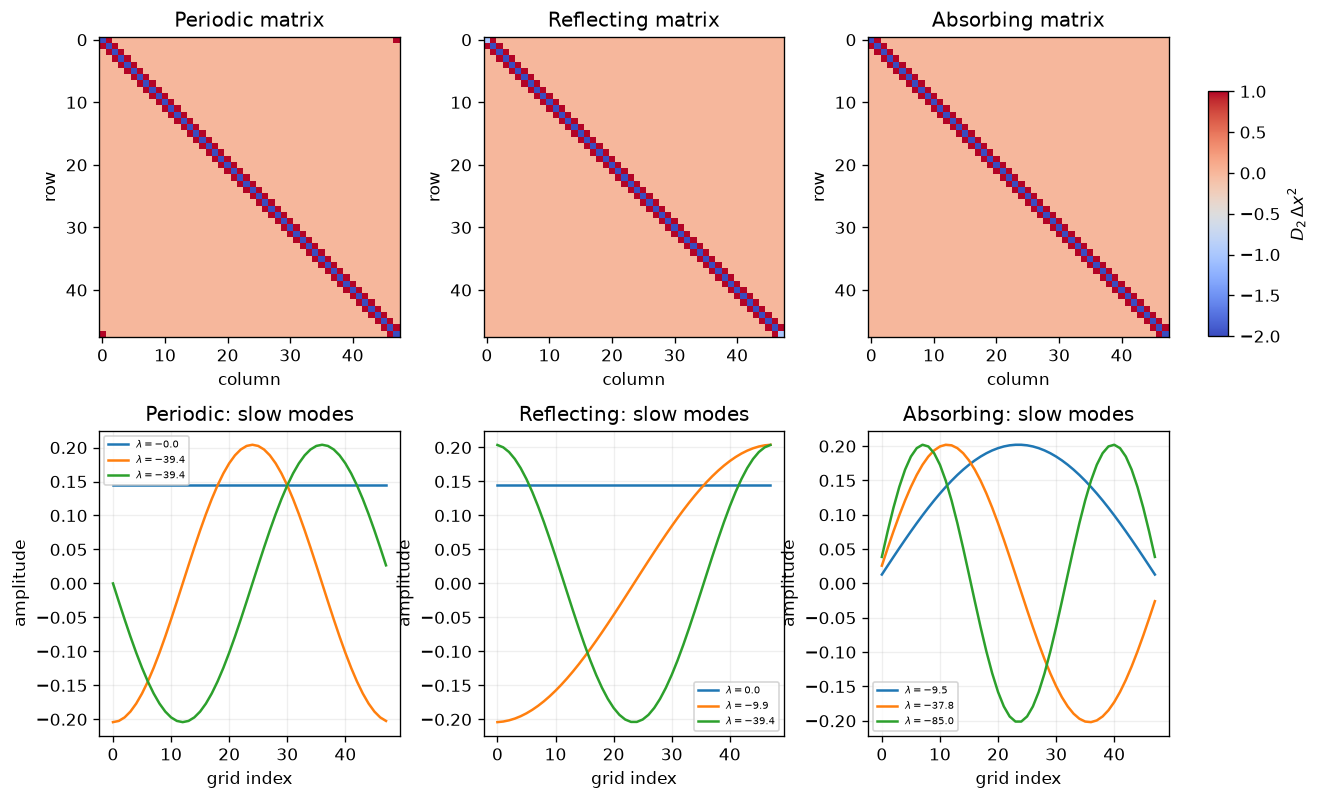

wrote lecture-notes/figures/08_brownian-motion-diffusion/09-finite-difference-laplacian.pdf


In [4]:
figure, axes = plt.subplots(2, 3, figsize=(11.0, 6.8))
coordinate = np.arange(grid_size)

for column, (name, matrix) in enumerate(matrices.items()):
    image = axes[0, column].imshow(matrix * spacing**2, cmap="coolwarm", vmin=-2.0, vmax=1.0)
    axes[0, column].set(title=f"{name} matrix", xlabel="column", ylabel="row")
    eigenvalue, eigenvector = eigensystems[name]
    for mode_offset in (1, 2, 3):
        mode_index = -mode_offset
        mode = eigenvector[:, mode_index]
        if np.sum(mode) < 0.0:
            mode = -mode
        axes[1, column].plot(
            coordinate,
            mode,
            label=rf"$\lambda={eigenvalue[mode_index]:.1f}$",
        )
    axes[1, column].set(title=f"{name}: slow modes", xlabel="grid index", ylabel="amplitude")
    axes[1, column].legend(fontsize=6)
    axes[1, column].grid(alpha=0.2)

figure.subplots_adjust(
    left=0.07,
    right=0.88,
    bottom=0.08,
    top=0.94,
    wspace=0.28,
    hspace=0.30,
)
colorbar_axis = figure.add_axes([0.91, 0.57, 0.015, 0.30])
figure.colorbar(
    image,
    cax=colorbar_axis,
    label=r"$D_2\,\Delta x^2$",
)
output_path = OUTPUT / "09-finite-difference-laplacian.pdf"
figure.savefig(
    output_path,
    bbox_inches="tight",
    metadata={"Creator": f"DLSU {ROOT.name.removeprefix('dlsu_')}", "CreationDate": None, "ModDate": None},
)
plt.show()
print(f"wrote {output_path.relative_to(ROOT)}")
